In [1]:
# 라이브러리 설치
%pip install -qU langchain langchain-openai langchain-community langchain-experimental
%pip install -qU langchain-chroma faiss-cpu langchain-teddynote
%pip install -qU langchain-tavily google-search-results pypdf
%pip install -qU mypy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# 라이브러리 import
from uuid import uuid4

# 타입 설정
# Sequence : 메시지들의 순서 있는 시퀀스(리스트) 객체 (list 또는 tuple 형태로 메시지를 저장)
# Literal : 값 자체를 타입으로 제한할 수 있도록 해주는 기능
from typing import Annotated, TypedDict, Dict, List, Sequence, Literal
# pydantic : Python 데이터 검증과 설정 관리를 위한 라이브러리
from pydantic import Field, BaseModel, ValidationError

# 상태, 노드
# 노드 : 그래프에서의 작업 단위, 실제 작업을 수행하는 함수
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
# 도구를 노드로 만드는 기능 (자동 맵핑, 상태업데이트, 다중 실행)
from langgraph.prebuilt import ToolNode
# 도구 노드의 결과에 따라 자동으로 라우팅 경로를 설정
from langgraph.prebuilt import tools_condition

# 메모리 저장소
from langgraph.checkpoint.memory import MemorySaver

# 실행 설정
from langchain_core.runnables import RunnableConfig

# 시각화
from IPython.display import Image, display, Markdown
from langchain_teddynote.messages import stream_graph

# 모델 설정
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate, MessagesPlaceholder
# BaseMessage : BaseMessage를 상속한 다양한 메시지 타입 (HumanMessage, AIMessage, SystemMessage)
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage

# 웹 검색 도구
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_tavily import TavilySearch

# 도구 정의 데코레이터
from langchain.tools import tool

# RAG 라이브러리
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

/var/folders/50/vkw7y7hx6xq4kqwy6y7p550h0000gn/T/ipykernel_36996/778573702.py:37: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [3]:
import os
os.environ['OPENAI_API_KEY'] = "YOUR_OPENAI_API_KEY"

In [4]:
# 웹 검색을 위한 Key 등록
os.environ['TAVILY_API_KEY'] = 'YOUR_TAVILY_API_KEY'

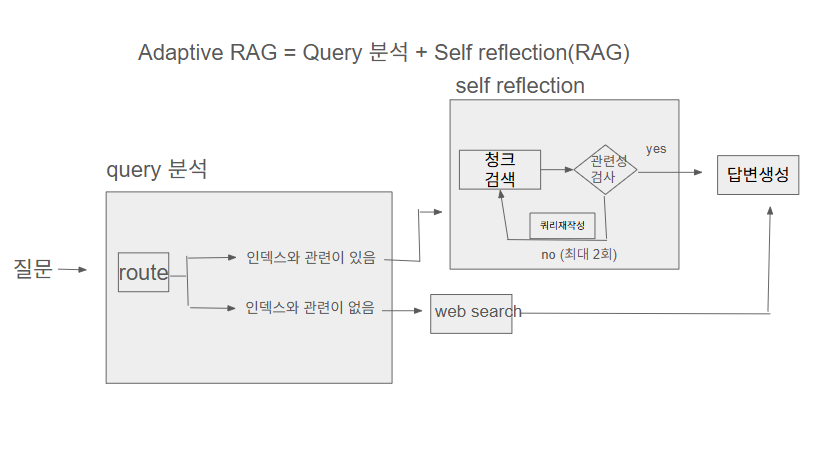

#### PDF기반 벡터스토어 준비

In [5]:
# 문서로드
loader = PyPDFLoader("/content/drive/MyDrive/Colab Notebooks/26.09.01 Agent(501호)/data/SPRi AI Brief_11월호산업동향.pdf")
documents = loader.load()
# Chunking 작업 : 작은 단위로 나누는 작업 -> 답변의 품질 향상 및 토큰비용 절약
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500, # 청크의 크기
    chunk_overlap = 100 # 청크끼리 겹치는 글자 수
)
texts = text_splitter.split_documents(documents) # 청킹작업 실시
# 임베딩 및 벡터DB 저장 (글자를 숫자로 변경하는 작업)
vec_db = FAISS.from_documents(texts, # 잘라낸 글자 묶음
                              OpenAIEmbeddings()) # 임베딩도구
# 검색기 생성
retreiver = vec_db.as_retriever(search_kwargs={"k":2}) # 검색기 생성

#### Query 분석을 위한 Router 노드 만들기

In [6]:
# 상태 클래스 정의
class AdaptiveRAGState(TypedDict) :
  question: Annotated[str, "User Question"] # 사용자질문
  context: Annotated[str, "list of datasource"] # 관련문서 검색 결과
  answer: Annotated[str, "LLM Answer"]# LLM의 답변
  relevance: Annotated[str, "relevance check result"]# 문서관련성 검사결과
  datasource: Annotated[str, "datasource type"]# RAG를 위한 datasource 유형
  current_repeat_num: Annotated[int, "current repeat num"]# 현재 쿼리 재작성 횟수
  max_repeat_num: Annotated[int, "max repeat num"]# 최대 쿼리 재작성 횟수

In [7]:
# query와 DB index의 관계를 이진분류하도록 구성 -> vectorstore / websearch
class QueryRouteResult(BaseModel) :
  datasource : Literal["vectorstore","websearch"] = Field(
      ... , # 필수입력 요소
      description="사용자 질문이 주어지면 websearch나 vectorstore로 라우팅하게 선택하세요."
  )

In [9]:
# 지정된 조건에 맞춰서 생성해야 에러가 없음
QueryRouteResult(datasource='vectorstore')

QueryRouteResult(datasource='vectorstore')

In [29]:
# query route chain 만들기
## 모델생성
llm = init_chat_model(model = "openai:gpt-4o-mini")
## 시스템 프롬프트 생성
system = """당신은 사용자 질문을 벡터스토어나 웹 검색으로 라우팅하는 전문가입니다.
벡터스토어에는 SPRI AI Bried 11월호 산업동향 관련 문서가 포함되어 있습니다. 주제들은 다음과 같다.
- 미국 민권위원회, 연방정부의 얼굴인식 기술 사용에 따른 민권 영향 분석
- 미국 백악관 예산관리국, 정부의 책임 있는 AI 조달을 위한 지침 발표
- 유로폴, 법 집행에서 AI의 이점과 과제를 다룬 보고서 발간 ·
- OECD, 공공 부문의 AI 도입을 위한 G7 툴킷 발표
- 세계경제포럼, 생성AI 시대의 거버넌스 프레임워크 제시
- CB인사이츠 분석 결과, 2024년 3분기 벤처 투자 31%가 AI 스타트업에 집중
- 메타, 동영상 생성AI 도구 ‘메타 무비 젠’ 공개
- 메타, 이미지와 텍스트 처리하는 첫 멀티모달 AI 모델 ‘라마 3.2’ 공개
- 앨런AI연구소, 벤치마크 평가에서 GPT-4o 능가하는 성능의 오픈소스 LLM ‘몰모’ 공개
- 미스트랄AI, 온디바이스용 AI 모델 ‘레 미니스트로’ 공개
- 카카오, 통합 AI 브랜드 겸 신규 AI 서비스 ‘카나나’ 공개
- 2024년 노벨 물리학상과 화학상, AI 관련 연구자들이 수상
- 미국 국무부, AI 연구에서 국제협력을 위한 ‘글로벌 AI 연구 의제’ 발표
- 일본 AI안전연구소, AI 안전성에 대한 평가 관점 가이드 발간
- 구글 딥마인드, 반도체 칩 레이아웃 설계하는 AI 모델 ‘알파칩’ 발표
- AI21 CEO, AI 에이전트에 트랜스포머 아키텍처의 대안 필요성 강조
- MIT 산업성과센터, 근로자 관점에서 자동화 기술의 영향 조사
- 다이스 조사, AI 전문가의 73%는 2025년 중 이직 고려
- 가트너 예측, AI로 인해 엔지니어링 인력의 80%가 역량 향상 필요
- 인디드 조사 결과, 생성AI가 인간 근로자 대체할 가능성은 희박

이러한 주제에 대한 질문이 있으면 벡터스토어를 사용하세요. 그렇지 않으면 웹 검색을 사용하십시오."""
## 템플릿 생성
route_template = ChatPromptTemplate.from_messages([
    ('system', system),
    ('human', "{query}")
])
## 연결
query_route_chain = route_template | llm.with_structured_output(QueryRouteResult)

# 쿼리분석 노드
def query_route(s:AdaptiveRAGState) -> AdaptiveRAGState :
  res = query_route_chain.invoke({"query" : s['question']})
  print("datasource : ", res.datasource)
  return {"datasource" : res.datasource}

### 웹서치 기능 구현하기(실습)

In [13]:
import json

In [14]:
# 검색도구 생성
tool_tavily = TavilySearch(max_results=3)

# 웹검색 노드 구성
def web_search(s: AdaptiveRAGState) -> AdaptiveRAGState :
  # 검색
  search_result = tool_tavily.invoke(s['question'])
  # 검색결과 통합
  context = "\n\n".join([ json.dumps({"page_content" : d["content"],"source" : d["url"],"page_num" : "페이지정보없음" }, ensure_ascii=False) for d in search_result['results'] ])
  return {"context" : context}

In [16]:
# 답변생성 노드
def llm_answer(s : AdaptiveRAGState) -> AdaptiveRAGState :
  # 프롬프트 설정
  system_prompt = '''
    당신은 유능한 AI동향 검색 어시스턴트입니다. 아래 검색된 내용을 바탕으로 답변하세요.
    답변시 참고한 Source(출처)를 표기하도록 해주세요. 출처에는 파일명, 페이지 번호등을 넣어서 보여주세요.

    {context}
  '''
  # 템플릿 생성
  template = ChatPromptTemplate.from_messages([
      ('system', system_prompt),
      ('human', "{input}")
  ])
  # 체인 구성하기
  chain = template | llm | StrOutputParser()
  # 체인 호출하기
  response = chain.invoke({"context" : s['context'], "input" : s['question']})

  # 생성된 답변 반환
  return {"answer" : response}

### Self reflection 기능구현

In [19]:
# 문서검색 노드
def retreive_node(s : AdaptiveRAGState) -> AdaptiveRAGState : # 노드의 입력인자와 반환타입 설정
  # 사용자 질문기반 검색 수행
  docs = retreiver.invoke(s['question'])
  # 검색된 Document 객체를 하나의 문자열로 병합
  context = "\n\n".join([ json.dumps({"page_content" : d.page_content,"source" : d.metadata['source'],"page_num" :  d.metadata['page'] }, ensure_ascii=False) for d in docs ])

  return {"context" : context} # 상태값에 실어서 반환

In [20]:
# 출력 구조 정의 -> Pydantic을 사용하여 yes or no 형태의 데이터로 강제
class RelevanceScore(BaseModel) : # AI가 주는 답변의 데이터 타입을 정의
  score : str = Field(description="사용자 질문(question)과 검색된 문서(context)가 관련 있으면 'yes', 없으면 'no' ")

# 관련성 체크 노드 구현
def relevance_check(s:AdaptiveRAGState) -> AdaptiveRAGState :
  # 구조화된 출력으로 설정한 LLM
  structured_llm = llm.with_structured_output(RelevanceScore)

  # 평가 프롬프트
  system_prompt = '''
    당신은 검색된 문서와 사용자 질문간의 관련성을 평가하는 역할입니다.
    검색된 문서(Context)가 사용자 질문(question)의 대답에 도움이 되는 정보를
    포함하고 있는지 확인해주세요.

    - 조금이라도 관련이 있다면 'yes'
    - 전혀 관련이 없는 내용이라면 'no'
    - 오직 'yes' 또는 'no'로 대답해주세요.
  '''
  # 템플릿 구성하기
  template = ChatPromptTemplate.from_messages([
      ('system', system_prompt),
      ('human', "Context : {context} \n\n Question : {question}")
  ])

  # 체인구성하기
  checker_chain = template | structured_llm
  # 실행
  response = checker_chain.invoke({"context": s['context'] , "question" : s['question']})
  # 확인용 출력
  print(f"=======[RELEVANCE CHECK] : {response.score}")
  # 상태 업데이트
  return {"relevance" : response.score}

In [40]:
# 쿼리 재작성 노드
def query_rewrite(s:AdaptiveRAGState) -> AdaptiveRAGState :
  current_num = s['current_repeat_num'] + 1
  if current_num > s['max_repeat_num'] :
    return {"current_repeat_num" : current_num}
  system = '''
    귀하는 입력 질문을 최적화된 더 나은 버전으로 변환하는 질문 재작성자입니다.
    벡터스토어 검색용 question을 보고 기본 의미론적 의도/의미에 대해서 추론해보세요.
    그리고 벡터스토어 검색에 활용할 수 있도록 개선된 질문을 재작성하세요.
  '''
  rewrite_template = ChatPromptTemplate.from_messages([
      ('system',system),
      ('human', "사용자 question : {question}")
  ])
  # 체인 구성 및 호출
  rewrite_chain = rewrite_template | llm | StrOutputParser()
  response = rewrite_chain.invoke({"question" : s['question']})
  # 확인용 출력
  print("기존 query : ", s['question'])
  print("재작성 query : ", response)
  return {"question" : response, "current_repeat_num" : current_num} # 기존 질문의 상태값에 덮어쓰기

### workflow 구성하기

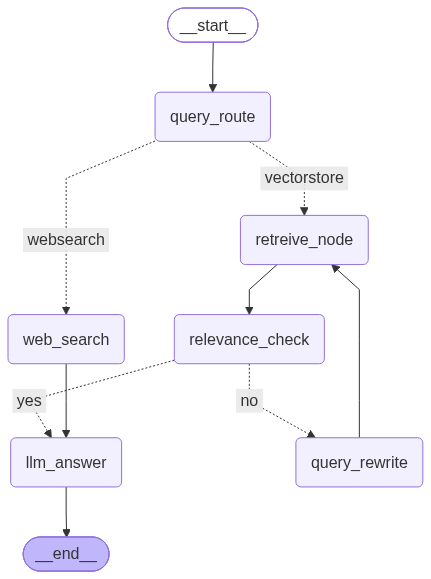

In [50]:
# 그래프 베이스 생성
workflow = StateGraph(AdaptiveRAGState)
# 노드추가
workflow.add_node("query_route", query_route)
workflow.add_node("web_search", web_search)
workflow.add_node("llm_answer", llm_answer)
workflow.add_node("retreive_node", retreive_node)
workflow.add_node("relevance_check", relevance_check)
workflow.add_node("query_rewrite", query_rewrite)
# 엣지추가
workflow.add_edge(START, "query_route")
## 조건부 엣지 추가
workflow.add_conditional_edges(
    "query_route",
    lambda x : x['datasource'],
    {"vectorstore" : "retreive_node", "websearch" : "web_search"}
)
workflow.add_edge("retreive_node", "relevance_check")

def is_relevance(s:AdaptiveRAGState) -> AdaptiveRAGState :
  if s['current_repeat_num'] > s['max_repeat_num'] :
    return 'yes'
  else :
    return s['relevance']

workflow.add_conditional_edges(
    "relevance_check",
    is_relevance,
    {"yes": "llm_answer" , "no" : "query_rewrite"}
)
workflow.add_edge("query_rewrite","retreive_node")
workflow.add_edge("web_search","llm_answer")
workflow.add_edge("llm_answer",END)
# 컴파일 및 시각화
app = workflow.compile()
display(Image(app.get_graph().draw_mermaid_png()))

In [34]:
# 테스트
print(app.invoke(input={"question" : "오늘 점심메뉴 추천해줘"}))
print(app.invoke(input={"question" : "새로운 카카오 AI 서비스 카나나에 대해서 성능평가가 어떻게 이뤄지고 있어?"}))

datasource :  websearch
{'question': '오늘 점심메뉴 추천해줘', 'context': '{"page_content": "| 오늘 뭐 먹지? 점심 메뉴 추천 17가지  프로파일 오일드림   ・  2023. 5. 3. 10:00  URL 복사  이웃추가 본문 기타 기능 공유하기  신고하기  오늘 뭐 먹지? 점심 메뉴 추천 17가지  ---  한국석유공사 대학생 SNS 서포터즈 윤예은입니다.  오늘은 고단한 업무시간을 버티게 해주는 점심시간,  뭘 먹을지 고민이 되는 여러분께 점심메뉴를 추천해 드립니다!  \u200b    1) 국밥  출처: 픽사베이  전날 과음했다면 속을 개운하게 풀어주는 국밥을 추천합니다.  순대국밥부터 뼈해장국, 콩나물국밥까지 다양한 종류의 국밥, 한국인은 역시 밥심!  ---  2) 파스타  출처: 픽사베이  오늘따라 느끼한 음식 또는 양식이 생각난다면 파스타로 어떠세요?  토마토, 로제, 크림, 알리오올리오까지 골라 먹는 재미의 파스타!  ---  3) 찌개요리  출처: 픽사베이  찌개 없이 못 사는 분을 위한 추천 메뉴입니다.  출출한 점심시간, 든든하게 배를 채워줄 뜨끈한 김치찌개, [...] 배를 채워줄 뜨끈한 김치찌개, 된장찌개, 부대찌개로 속을 채워보세요!  ---  4) 중화요리  출처: 픽사베이  짜장면, 짬뽕, 마파두부밥, 탕수육, 깐풍기, 볶음밥 등 다양한 중화요리의 세계!  고르기 힘든 만큼 골라 먹는 재미도 있는 중화요리, 오늘 점심 메뉴로 어떠세요?  ---  5) 초밥&우동  출처: 픽사베이  깔끔하게 점심 식사를 하고 싶다면 추천하는 메뉴입니다.  초밥 먹고 남은 약간의 허기짐을 완벽하게 채워줄 환상의 짝꿍 뜨끈한 우동도 드셔 보세요!  ---  6) 분식  출처: 픽사베이  학창시절 우리의 지갑을 책임졌던 분식!  김밥과 라면, 그리고 떡볶이와 순대, 튀김, 어묵 꼬치까지  저렴한 가격에 든든히 배를 채울 수 있는 최고의 선택입니다.  ---  7) 토스트, 샌드위치  출처: 픽사베이

In [53]:
print(app.invoke(input={"question" : "새로운 카카오 AI 서비스 카나나에 대한 모델 정확도",
                        "current_repeat_num" : 0,
                        "max_repeat_num": 2}))

datasource :  vectorstore
=======[RELEVANCE CHECK] : no
기존 query :  새로운 카카오 AI 서비스 카나나에 대한 모델 정확도
재작성 query :  개선된 질문: 카카오의 새로운 AI 서비스인 카나나의 모델 정확도는 어떻게 되나요?
=======[RELEVANCE CHECK] : no
기존 query :  개선된 질문: 카카오의 새로운 AI 서비스인 카나나의 모델 정확도는 어떻게 되나요?
재작성 query :  개선된 질문: 카카오의 새로운 AI 서비스 카나나의 모델 정확도는 얼마인가요?
=======[RELEVANCE CHECK] : no
=======[RELEVANCE CHECK] : no
{'question': '개선된 질문: 카카오의 새로운 AI 서비스 카나나의 모델 정확도는 얼마인가요?', 'context': '{"page_content": "1. 정책/법제  2. 기업/산업 3. 기술/연구  4. 인력/교육\\n11\\n카카오, 통합 AI 브랜드 겸 신규 AI 서비스 ‘카나나’ 공개\\nn 카카오가 대화의 맥락 속에서 주요 정보를 기억해 이용자에게 최적화된 답변을 제공하는 AI \\n메이트 서비스인 ‘카나나’를 공개 했으며 카카오톡과 별개의 앱으로 출시 예정\\nn 카카오는 자체 언어모델로 용량 별로 카나나 플래그, 카나나 에센스, 카나나 나노도 개발 \\n중으로, 에센스와 나노를 중심으로 주요 서비스에 적용할 계획 \\nKEY Contents\\n£ 카카오의 신규 AI 서비스 ‘카나나’, 개인메이트 ‘나나’와 그룹메이트 ‘카나’로 구현 \\nn 카카오가 2024년 10월 22~24일 열린 개발자 컨퍼런스 ‘if(kakaoAI)2024’에서 그룹 전체의 \\nAI 비전과 방향성을 공개하고 통합 AI 브랜드 ‘카나나(Kanana)’를 발표\\n∙ 사명인 카카오와 함께, ‘나에게 배워 나처럼 생각하고 행동한다’는 의미의 네이티브(Native), ‘배우지", "source": "/content/drive/